In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    mean_squared_error,
    r2_score
)
print("Libraries imported successfully for Model 2.")

Libraries imported successfully for Model 2.


In [2]:
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

In [3]:
accepted_file = "accepted.csv" if os.path.exists("accepted.csv") else "accepted_2007_to_2018Q4.csv"
stage2_cols = [
    'loan_amnt',           # Loan amount
    'term',                # 36 months or 60 months
    'int_rate',            # Interest rate (%)
    'installment',         # Monthly installment payment
    'grade',               # Loan grade (A, B, C, D, E, F, G)
    'emp_length',          # Employment length
    'home_ownership',      # RENT, MORTGAGE, OWN (Used for Subgroup Error Testing!)
    'annual_inc',          # Annual income
    'verification_status', # Income verification status
    'purpose',             # Reason for loan
    'dti',                 # Debt-to-Income ratio
    'fico_range_low',      # FICO credit score
    'open_acc',            # Open credit accounts
    'revol_bal',           # Revolving credit balance
    'revol_util',          # Revolving credit utilization (%)
    'loan_status'          # Target column (Fully Paid vs Charged Off)
]
df_raw2 = pd.read_csv(accepted_file, usecols=stage2_cols, nrows=30000)
df_model2 = df_raw2[df_raw2['loan_status'].isin(['Fully Paid', 'Charged Off'])].copy()
df_model2['repayment_risk'] = np.where(df_model2['loan_status'] == 'Fully Paid', 0, 1)
df_model2 = df_model2.drop(columns=['loan_status'])
if len(df_model2) > 20000:
    df_model2 = df_model2.sample(n=20000, random_state=42).reset_index(drop=True)
print("Model 2 Dataset Shape:", df_model2.shape)
df_model2.head()

Model 2 Dataset Shape: (20000, 16)


,loan_amnt,term,int_rate,installment,grade,emp_length,home_ownership,annual_inc,verification_status,purpose,dti,fico_range_low,open_acc,revol_bal,revol_util,repayment_risk
0,7875.0,36 months,13.18,266.03,C,2 years,RENT,44000.0,Source Verified,debt_consolidation,37.94,695.0,20.0,4024.0,47.9,0
1,12000.0,36 months,10.64,390.83,B,10+ years,RENT,73000.0,Not Verified,debt_consolidation,14.99,725.0,17.0,22344.0,25.1,0
2,20000.0,60 months,11.22,437.05,B,2 years,MORTGAGE,200000.0,Source Verified,credit_card,10.18,740.0,4.0,32278.0,69.4,0
3,29000.0,60 months,8.49,594.84,B,10+ years,MORTGAGE,101000.0,Verified,debt_consolidation,7.69,715.0,14.0,29310.0,43.0,0
4,10800.0,36 months,7.26,334.76,A,8 years,RENT,120000.0,Not Verified,credit_card,25.86,725.0,18.0,10853.0,45.2,1


In [4]:
print("Shape of Model 2 dataset:", df_model2.shape)
print("\nDataset Info:")
df_model2.info()
print("\nTarget Class Distribution (0 = Fully Paid, 1 = Charged Off / Default):")
print(df_model2['repayment_risk'].value_counts())

Shape of Model 2 dataset: (20000, 16)

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   loan_amnt            20000 non-null  float64
 1   term                 20000 non-null  str    
 2   int_rate             20000 non-null  float64
 3   installment          20000 non-null  float64
 4   grade                20000 non-null  str    
 5   emp_length           18730 non-null  str    
 6   home_ownership       20000 non-null  str    
 7   annual_inc           20000 non-null  float64
 8   verification_status  20000 non-null  str    
 9   purpose              20000 non-null  str    
 10  dti                  19999 non-null  float64
 11  fico_range_low       20000 non-null  float64
 12  open_acc             20000 non-null  float64
 13  revol_bal            20000 non-null  float64
 14  revol_util           19989 non-null  float64

In [5]:
# 3.1 Clean Text Columns in Model 2 (' 36 months' -> 36, '10+ years' -> 10.0)

# Convert term (' 36 months' or ' 60 months') to integer (36 or 60)
df_model2['term'] = df_model2['term'].astype(str).str.replace('months', '').str.strip()
df_model2['term'] = pd.to_numeric(df_model2['term'], errors='coerce')

# Convert emp_length to numeric
def clean_emp_length(val):
    if pd.isna(val):
        return np.nan
    val = str(val).strip()
    if '<' in val:
        return 0.5
    if '10+' in val:
        return 10.0
    for word in val.split():
        if word.isdigit():
            return float(word)
    return np.nan

df_model2['emp_length'] = df_model2['emp_length'].apply(clean_emp_length)

print("Data types after text cleaning:")
print(df_model2.dtypes)

Data types after text cleaning:
loan_amnt              float64
term                     int64
int_rate               float64
installment            float64
grade                      str
emp_length             float64
home_ownership             str
annual_inc             float64
verification_status        str
purpose                    str
dti                    float64
fico_range_low         float64
open_acc               float64
revol_bal              float64
revol_util             float64
repayment_risk           int64
dtype: object


In [6]:
# 3.2 Check Missing Values Before Cleaning
print("Missing values BEFORE cleaning:")
print(df_model2.isnull().sum())

# Fill numeric columns with Median
num_cols_m2 = [
    'loan_amnt', 'term', 'int_rate', 'installment', 'emp_length',
    'annual_inc', 'dti', 'fico_range_low', 'open_acc', 'revol_bal', 'revol_util'
]
for col in num_cols_m2:
    df_model2[col] = df_model2[col].fillna(df_model2[col].median())

# Fill categorical columns with Mode
cat_cols_m2 = ['grade', 'home_ownership', 'verification_status', 'purpose']
for col in cat_cols_m2:
    df_model2[col] = df_model2[col].fillna(df_model2[col].mode()[0])

print("\nMissing values AFTER cleaning:")
print(df_model2.isnull().sum())

# 3.3 Check and Remove Duplicates
print("\nDuplicate rows found:", df_model2.duplicated().sum())
df_model2 = df_model2.drop_duplicates().reset_index(drop=True)

# 3.4 Handle Extreme Outliers (Cap income, DTI, and revolving balance at 99th percentile)
df_model2['annual_inc'] = df_model2['annual_inc'].clip(upper=df_model2['annual_inc'].quantile(0.99))
df_model2['dti'] = df_model2['dti'].clip(lower=0, upper=df_model2['dti'].quantile(0.99))
df_model2['revol_bal'] = df_model2['revol_bal'].clip(upper=df_model2['revol_bal'].quantile(0.99))
df_model2['revol_util'] = df_model2['revol_util'].clip(lower=0, upper=100)

print("Cleaned Model 2 Shape:", df_model2.shape)
df_model2.describe()

Missing values BEFORE cleaning:
loan_amnt                 0
term                      0
int_rate                  0
installment               0
grade                     0
emp_length             1270
home_ownership            0
annual_inc                0
verification_status       0
purpose                   0
dti                       1
fico_range_low            0
open_acc                  0
revol_bal                 0
revol_util               11
repayment_risk            0
dtype: int64

Missing values AFTER cleaning:
loan_amnt              0
term                   0
int_rate               0
installment            0
grade                  0
emp_length             0
home_ownership         0
annual_inc             0
verification_status    0
purpose                0
dti                    0
fico_range_low         0
open_acc               0
revol_bal              0
revol_util             0
repayment_risk         0
dtype: int64

Duplicate rows found: 0
Cleaned Model 2 Shape: (20000, 16)


,loan_amnt,term,int_rate,installment,emp_length,annual_inc,dti,fico_range_low,open_acc,revol_bal,revol_util,repayment_risk
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,14345.655000,41.354400,12.002256,429.868803,5.946775,76073.248107,19.120173,694.860750,12.007900,16090.498550,50.927645,0.205550
std,8639.578863,9.992046,4.183365,255.630726,3.560536,43202.686170,8.674190,31.550264,5.721789,16039.965668,24.244979,0.404113
min,1000.000000,36.000000,5.320000,30.540000,0.500000,0.000000,0.000000,660.000000,1.000000,0.000000,0.000000,0.000000
25%,7525.000000,36.000000,9.170000,243.230000,3.000000,47000.000000,12.520000,670.000000,8.000000,5930.000000,32.600000,0.000000
50%,12000.000000,36.000000,11.480000,369.930000,6.000000,65000.000000,18.690000,685.000000,11.000000,11340.000000,50.600000,0.000000
75%,20000.000000,36.000000,14.480000,574.340000,10.000000,94000.000000,25.440000,710.000000,15.000000,20366.000000,69.500000,0.000000
max,35000.000000,60.000000,28.990000,1354.660000,10.000000,260000.000000,38.370000,845.000000,67.000000,96400.020000,100.000000,1.000000


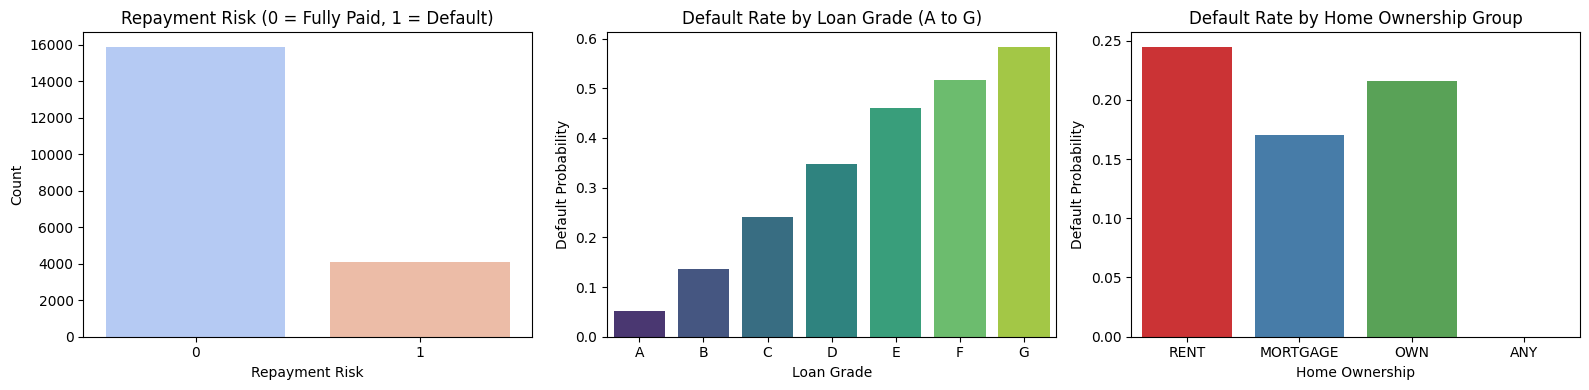

In [7]:
# 4.1 Repayment Risk Distribution & Subgroup Patterns (Model 2)
plt.figure(figsize=(16, 4))

# Plot 1: Target Class Distribution (0 = Fully Paid, 1 = Charged Off)
plt.subplot(1, 3, 1)
sns.countplot(x='repayment_risk', data=df_model2, palette='coolwarm')
plt.title('Repayment Risk (0 = Fully Paid, 1 = Default)')
plt.xlabel('Repayment Risk')
plt.ylabel('Count')

# Plot 2: Default Rate by Loan Grade (A to G)
plt.subplot(1, 3, 2)
grade_order = sorted(df_model2['grade'].unique())
sns.barplot(x='grade', y='repayment_risk', data=df_model2, order=grade_order, palette='viridis', errorbar=None)
plt.title('Default Rate by Loan Grade (A to G)')
plt.xlabel('Loan Grade')
plt.ylabel('Default Probability')

# Plot 3: Default Rate by Applicant Group (Home Ownership)
plt.subplot(1, 3, 3)
sns.barplot(x='home_ownership', y='repayment_risk', data=df_model2, palette='Set1', errorbar=None)
plt.title('Default Rate by Home Ownership Group')
plt.xlabel('Home Ownership')
plt.ylabel('Default Probability')

plt.tight_layout()
plt.show()

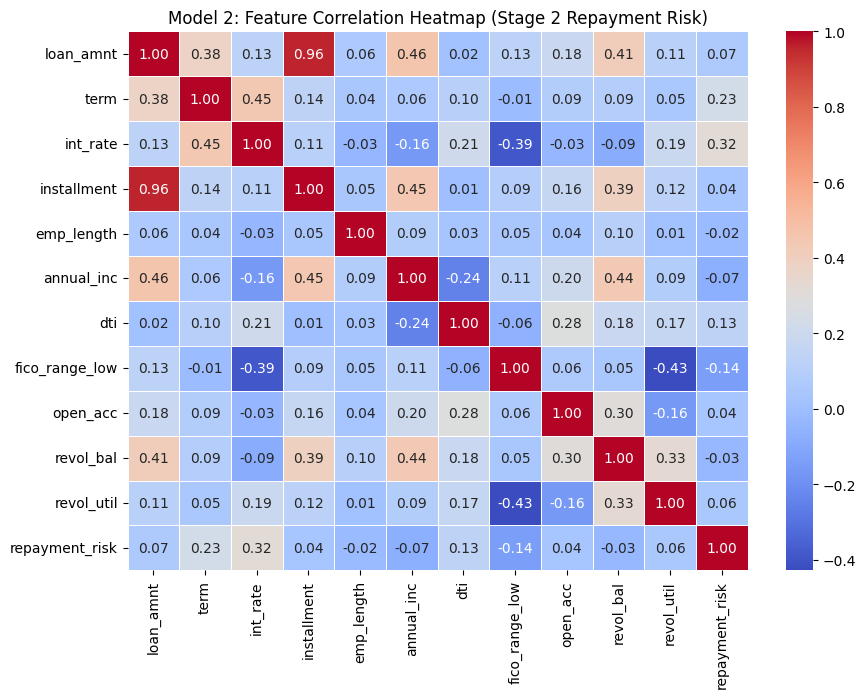

In [8]:
# 4.2 Correlation Heatmap of Numeric Features (Model 2)
plt.figure(figsize=(10, 7))
corr_m2 = df_model2.corr(numeric_only=True)
sns.heatmap(corr_m2, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Model 2: Feature Correlation Heatmap (Stage 2 Repayment Risk)')
plt.show()

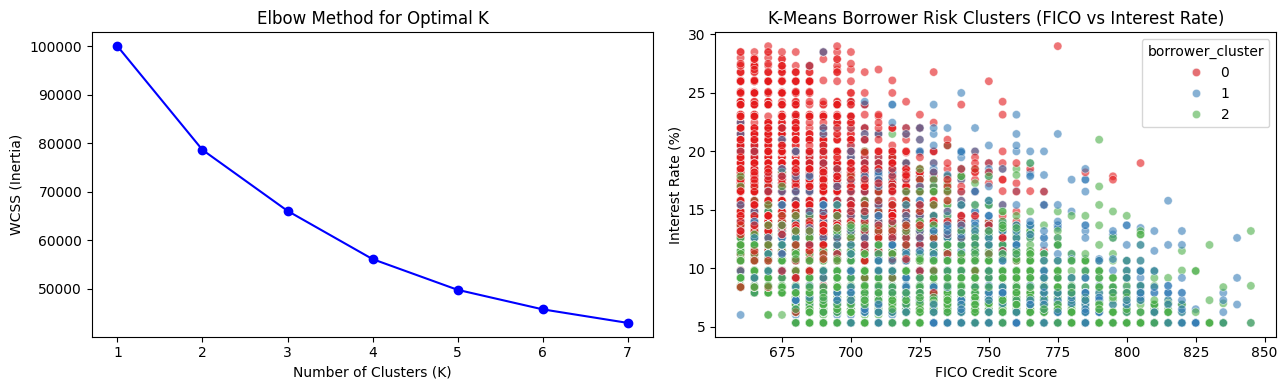


K-Means Borrower Cluster Summary:
                  loan_amnt  int_rate  annual_inc    dti  fico_range_low  \
borrower_cluster                                                           
0                  13356.67     15.41    56502.43  25.87          680.70   
1                  24843.15     11.02   129267.62  16.38          707.41   
2                   9669.32      9.82    63872.81  15.21          699.52   

                  repayment_risk  
borrower_cluster                  
0                           0.33  
1                           0.16  
2                           0.13  


In [9]:
# 4.3 Unsupervised Borrower Profiling using K-Means Clustering (Syllabus Model)
cluster_features = ['loan_amnt', 'int_rate', 'annual_inc', 'dti', 'fico_range_low']
X_cluster = df_model2[cluster_features].copy()

# Scale features before K-Means (Required for distance-based clustering)
scaler_kmeans = StandardScaler()
X_cluster_scaled = scaler_kmeans.fit_transform(X_cluster)

# 1. Elbow Method to find optimal number of clusters (K)
wcss = []
for k in range(1, 8):
    km = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    km.fit(X_cluster_scaled)
    wcss.append(km.inertia_)

# Fit K-Means with K = 3 (Low-Risk, Medium-Risk, High-Risk Borrower Profiles)
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=42, n_init=10)
df_model2['borrower_cluster'] = kmeans.fit_predict(X_cluster_scaled)

# Plot Elbow Curve and Cluster Scatter Plot
plt.figure(figsize=(13, 4))

plt.subplot(1, 2, 1)
plt.plot(range(1, 8), wcss, marker='o', color='blue')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')

plt.subplot(1, 2, 2)
sns.scatterplot(
    x=df_model2['fico_range_low'],
    y=df_model2['int_rate'],
    hue=df_model2['borrower_cluster'],
    palette='Set1',
    alpha=0.6
)
plt.title('K-Means Borrower Risk Clusters (FICO vs Interest Rate)')
plt.xlabel('FICO Credit Score')
plt.ylabel('Interest Rate (%)')

plt.tight_layout()
plt.show()

# Show average values and default rate per cluster
print("\nK-Means Borrower Cluster Summary:")
print(df_model2.groupby('borrower_cluster')[cluster_features + ['repayment_risk']].mean().round(2))

In [10]:
# 5.1 Feature Engineering (Model 2)
df_model2['loan_to_income'] = df_model2['loan_amnt'] / (df_model2['annual_inc'] + 1)
df_model2['installment_to_monthly_inc'] = df_model2['installment'] / ((df_model2['annual_inc'] / 12.0) + 1)

# Separate independent variables (X) and target variable (y)
# Drop borrower_cluster if created during EDA so only pure pre-loan features are used
cols_to_drop = ['repayment_risk']
if 'borrower_cluster' in df_model2.columns:
    cols_to_drop.append('borrower_cluster')

X_m2 = df_model2.drop(columns=cols_to_drop)
y_m2 = df_model2['repayment_risk']

# Save applicant group columns (home_ownership & grade) for our Step 8 Subgroup Error Audit
applicant_groups_df = df_model2[['home_ownership', 'grade', 'annual_inc', 'loan_amnt', 'int_rate']].copy()

# 5.2 One-Hot Encoding BEFORE Train-Test Split (Exact College PDF Style)
X_m2 = pd.get_dummies(
    X_m2,
    columns=['grade', 'home_ownership', 'verification_status', 'purpose'],
    drop_first=True
)

print("Shape after One-Hot Encoding:", X_m2.shape)
print("y_m2 shape:", y_m2.shape)
X_m2.head()

Shape after One-Hot Encoding: (20000, 35)
y_m2 shape: (20000,)


,loan_amnt,term,int_rate,installment,emp_length,annual_inc,dti,fico_range_low,open_acc,revol_bal,...,purpose_debt_consolidation,purpose_home_improvement,purpose_house,purpose_major_purchase,purpose_medical,purpose_moving,purpose_other,purpose_renewable_energy,purpose_small_business,purpose_vacation
0,7875.0,36,13.18,266.03,2.0,44000.0,37.94,695.0,20.0,4024.0,...,True,False,False,False,False,False,False,False,False,False
1,12000.0,36,10.64,390.83,10.0,73000.0,14.99,725.0,17.0,22344.0,...,True,False,False,False,False,False,False,False,False,False
2,20000.0,60,11.22,437.05,2.0,200000.0,10.18,740.0,4.0,32278.0,...,False,False,False,False,False,False,False,False,False,False
3,29000.0,60,8.49,594.84,10.0,101000.0,7.69,715.0,14.0,29310.0,...,True,False,False,False,False,False,False,False,False,False
4,10800.0,36,7.26,334.76,8.0,120000.0,25.86,725.0,18.0,10853.0,...,False,False,False,False,False,False,False,False,False,False


In [11]:
# 5.3 Train-Test Split (80% Train, 20% Test with stratify=y_m2)
X_train_m2, X_test_m2, y_train_m2, y_test_m2 = train_test_split(
    X_m2,
    y_m2,
    test_size=0.20,
    random_state=42,
    stratify=y_m2
)

# Also align the test set applicant groups using X_test_m2.index for Step 8 Fairness Audit
groups_test_m2 = applicant_groups_df.loc[X_test_m2.index].copy()

print("Training data:", X_train_m2.shape)
print("Testing data :", X_test_m2.shape)

# 5.4 Feature Scaling (Fit ONLY on X_train_m2)
scaler_m2 = StandardScaler()
X_train_m2_scaled = scaler_m2.fit_transform(X_train_m2)
X_test_m2_scaled = scaler_m2.transform(X_test_m2)

# 5.5 Apply SMOTE ONLY to the Training Data (Exact Day 4 PDF Rule)
from imblearn.over_sampling import SMOTE

print("\nBefore SMOTE (Training Set):")
print(y_train_m2.value_counts())

smote = SMOTE(random_state=42)
X_train_m2_balanced, y_train_m2_balanced = smote.fit_resample(
    X_train_m2_scaled,
    y_train_m2
)

print("\nAfter SMOTE (Training Set Balanced):")
print(y_train_m2_balanced.value_counts())

Training data: (16000, 35)
Testing data : (4000, 35)

Before SMOTE (Training Set):
repayment_risk
0    12711
1     3289
Name: count, dtype: int64

After SMOTE (Training Set Balanced):
repayment_risk
0    12711
1    12711
Name: count, dtype: int64


Total original encoded features: 35
Number of components required for 95% variance: 26
Variance retained: 96.08 %


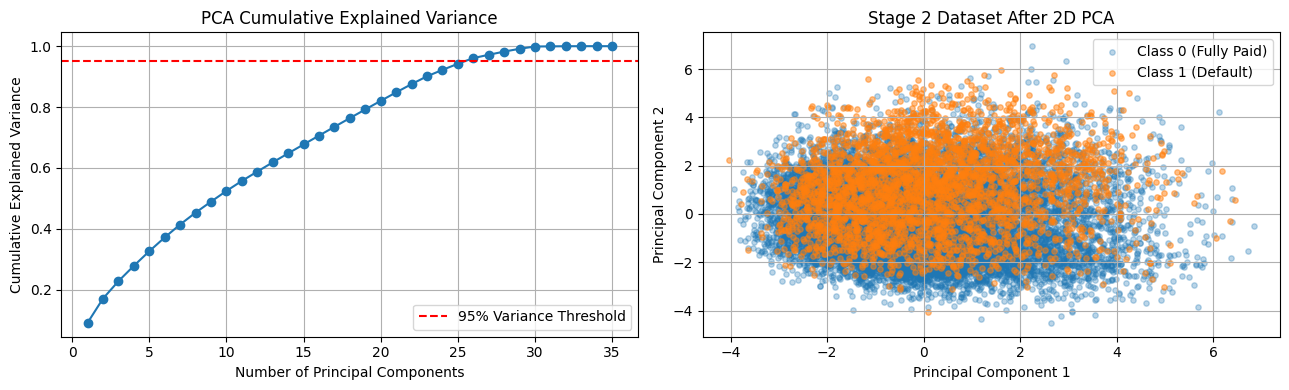

In [12]:
# 5.6 Applying PCA & Cumulative Explained Variance (Exact Day 10 PDF Style)
pca_full = PCA()
X_train_pca_full = pca_full.fit_transform(X_train_m2_scaled)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# Find number of components required for 95% variance (Exact Day 10 Cell 13 formula)
n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1
print("Total original encoded features:", X_train_m2_scaled.shape[1])
print("Number of components required for 95% variance:", n_components_95)
print("Variance retained:", round(cumulative_variance[n_components_95 - 1] * 100, 2), "%")

# Create the 95% variance reduced dataset for fast model comparison
pca_95 = PCA(n_components=n_components_95, random_state=42)
X_train_m2_pca = pca_95.fit_transform(X_train_m2_scaled)
X_test_m2_pca = pca_95.transform(X_test_m2_scaled)

# Plot Cumulative Explained Variance and 2D PCA Projection
plt.figure(figsize=(13, 4))

plt.subplot(1, 2, 1)
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o')
plt.axhline(y=0.95, color='r', linestyle='--', label='95% Variance Threshold')
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Cumulative Explained Variance")
plt.legend()
plt.grid(True)

# 2D PCA for Visualization (PC1 vs PC2)
pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_train_m2_scaled)

plt.subplot(1, 2, 2)
plt.scatter(X_pca_2d[y_train_m2 == 0, 0], X_pca_2d[y_train_m2 == 0, 1], label='Class 0 (Fully Paid)', alpha=0.3, s=15)
plt.scatter(X_pca_2d[y_train_m2 == 1, 0], X_pca_2d[y_train_m2 == 1, 1], label='Class 1 (Default)', alpha=0.5, s=15)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Stage 2 Dataset After 2D PCA")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [13]:
# 6.1 Initialize Allowed Syllabus Classification Models for Stage 2 (Repayment Risk)

# 1. Logistic Regression (L2 Ridge Penalty & L1 Lasso Penalty)
log_reg_l2_m2 = LogisticRegression(penalty='l2', C=1.0, max_iter=1000, random_state=42)
log_reg_l1_m2 = LogisticRegression(penalty='l1', solver='liblinear', C=1.0, max_iter=1000, random_state=42)

# 2. K-Nearest Neighbors (K=5 baseline before GridSearchCV/RandomizedSearchCV in Step 9)
knn_m2 = KNeighborsClassifier(n_neighbors=5)

# 3. Gaussian Naive Bayes (Will be compared Before vs After SMOTE as in Day 4 PDF)
nb_baseline_m2 = GaussianNB()
nb_smote_m2 = GaussianNB()

# 4. Support Vector Machines (Linear, Polynomial, and RBF Kernels as in Day 5 PDF)
svm_linear_m2 = SVC(kernel='linear', C=1, probability=True, random_state=42)
svm_poly_m2 = SVC(kernel='poly', degree=3, C=1, gamma='scale', probability=True, random_state=42)
svm_rbf_m2 = SVC(kernel='rbf', C=1, gamma='scale', probability=True, random_state=42)

# 5. Decision Tree Classifier (Gini Impurity as in Day 7 PDF)
dt_m2 = DecisionTreeClassifier(criterion='gini', random_state=42)

# 6. Random Forest Classifier (100 trees as in Day 7 PDF)
rf_m2 = RandomForestClassifier(n_estimators=100, random_state=42)

print("All Stage 2 classification models initialized successfully.")

All Stage 2 classification models initialized successfully.


In [14]:
# ==============================================================================
# STEP 6.2: Initialize Syllabus Regression Models (Exact Exercise 2 PDF Style)
# ==============================================================================
from sklearn.pipeline import Pipeline

# Prepare single-feature (FICO Score) -> target (Interest Rate)
X_reg = df_model2[['fico_range_low']].values
y_reg = df_model2['int_rate'].values

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42
)

# 1. Simple Linear Regression
lin_reg_model = LinearRegression()

# 2. Polynomial Regression (Degree = 6)
poly_features = PolynomialFeatures(degree=6)
poly_reg_model = LinearRegression()

# 3. Ridge Regression (L2 Regularization Pipeline)
ridge_model = Pipeline([
    ('poly', PolynomialFeatures(degree=6)),
    ('scaler', StandardScaler()),
    ('ridge', Ridge(alpha=1.0))
])

# 4. Lasso Regression (L1 Regularization Pipeline)
lasso_model = Pipeline([
    ('poly', PolynomialFeatures(degree=6)),
    ('scaler', StandardScaler()),
    ('lasso', Lasso(alpha=0.05, max_iter=10000))
])

print("Linear, Polynomial, Ridge (L2), and Lasso (L1) regression models initialized.")

Linear, Polynomial, Ridge (L2), and Lasso (L1) regression models initialized.


In [15]:
# ==============================================================================
# STEP 7.2: MODEL TRAINING (STAGE 2: INTEREST RATE PRICING REGRESSION)
# ==============================================================================
print("Training Stage 2 regression models (Linear, Polynomial, Ridge, Lasso)...")

# 1. Simple Linear Regression
lin_reg_model.fit(X_reg_train, y_reg_train)

# 2. Polynomial Regression (Fit transform the training data first)
X_reg_train_poly = poly_features.fit_transform(X_reg_train)
poly_reg_model.fit(X_reg_train_poly, y_reg_train)

# 3. Ridge Regression (L2 Pipeline handles its own polynomial transformation)
ridge_model.fit(X_reg_train, y_reg_train)

# 4. Lasso Regression (L1 Pipeline handles its own polynomial transformation)
lasso_model.fit(X_reg_train, y_reg_train)

print("All Stage 2 regression models trained successfully.")

Training Stage 2 regression models (Linear, Polynomial, Ridge, Lasso)...
All Stage 2 regression models trained successfully.


In [16]:
# ==============================================================================
# STEP 7.2: MODEL TRAINING (STAGE 2: INTEREST RATE PRICING REGRESSION)
# ==============================================================================

print("Training Stage 2 regression models (Linear, Polynomial, Ridge, Lasso)...")

# 1. Simple Linear Regression
lin_reg_model.fit(X_reg_train, y_reg_train)

# 2. Polynomial Regression
X_reg_train_poly = poly_features.fit_transform(X_reg_train)
poly_reg_model.fit(X_reg_train_poly, y_reg_train)

# 3. Ridge Regression (L2 Pipeline)
ridge_model.fit(X_reg_train, y_reg_train)

# 4. Lasso Regression (L1 Pipeline)
lasso_model.fit(X_reg_train, y_reg_train)

print("All Stage 2 regression models trained successfully.")

Training Stage 2 regression models (Linear, Polynomial, Ridge, Lasso)...
All Stage 2 regression models trained successfully.


In [17]:
# Train the Random Forest classifier on the balanced training data
rf_m2.fit(X_train_m2_balanced, y_train_m2_balanced)
print("Random Forest model trained successfully.")

Random Forest model trained successfully.


Model 2 (Random Forest on SMOTE Data) Evaluation:
Accuracy: 0.769
Precision (Default): 0.4269340974212034
Recall (Default): 0.36253041362530414
F1 Score (Default): 0.39210526315789473

Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.87      0.86      3178
           1       0.43      0.36      0.39       822

    accuracy                           0.77      4000
   macro avg       0.63      0.62      0.62      4000
weighted avg       0.76      0.77      0.76      4000



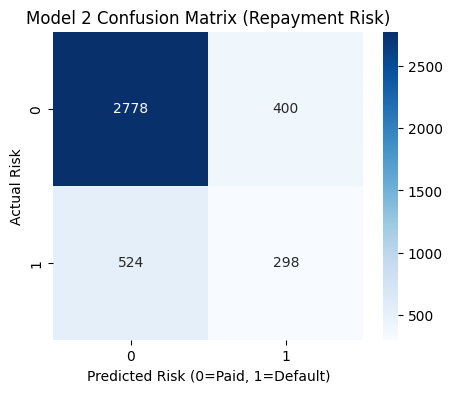


Subgroup Error Analysis by Home Ownership:
                Total_Applicants  Default_Rate_Actual  Default_Rate_Predicted  \
home_ownership                                                                  
MORTGAGE                  1906.0               0.1700                  0.1401   
OWN                        494.0               0.2368                  0.1518   
RENT                      1600.0               0.2381                  0.2225   

                Error_Rate  
home_ownership              
MORTGAGE            0.2072  
OWN                 0.2267  
RENT                0.2606  


In [18]:
# ==============================================================================
# STEP 8: MODEL EVALUATION & SUBGROUP FAIRNESS AUDIT (MODEL 2)
# ==============================================================================

# 1. Evaluate Random Forest / Logistic Regression on Test Set
y_pred_m2 = rf_m2.predict(X_test_m2_scaled)
y_proba_m2 = rf_m2.predict_proba(X_test_m2_scaled)[:, 1]

print("Model 2 (Random Forest on SMOTE Data) Evaluation:")
print("Accuracy:", accuracy_score(y_test_m2, y_pred_m2))
print("Precision (Default):", precision_score(y_test_m2, y_pred_m2))
print("Recall (Default):", recall_score(y_test_m2, y_pred_m2))
print("F1 Score (Default):", f1_score(y_test_m2, y_pred_m2))

print("\nClassification Report:\n", classification_report(y_test_m2, y_pred_m2))

# 2. Confusion Matrix Heatmap
cm_m2 = confusion_matrix(y_test_m2, y_pred_m2)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_m2, annot=True, fmt='d', cmap='Blues')
plt.title("Model 2 Confusion Matrix (Repayment Risk)")
plt.xlabel("Predicted Risk (0=Paid, 1=Default)")
plt.ylabel("Actual Risk")
plt.show()

# 3. Subgroup Fairness Audit (Rubric Requirement: Test whether errors differ across groups)
groups_test_m2['actual_risk'] = y_test_m2.values
groups_test_m2['predicted_risk'] = y_pred_m2

print("\nSubgroup Error Analysis by Home Ownership:")
subgroup_summary = groups_test_m2.groupby('home_ownership').apply(
    lambda g: pd.Series({
        'Total_Applicants': len(g),
        'Default_Rate_Actual': g['actual_risk'].mean().round(4),
        'Default_Rate_Predicted': g['predicted_risk'].mean().round(4),
        'Error_Rate': (g['actual_risk'] != g['predicted_risk']).mean().round(4)
    })
)
print(subgroup_summary)

In [19]:
# ==============================================================================
# STEP 9.1: HYPERPARAMETER TUNING FOR KNN USING GridSearchCV (MODEL 2)
# ==============================================================================
from sklearn.model_selection import GridSearchCV

param_grid_knn = {
    'n_neighbors': [3, 5, 7, 11, 15],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

grid_search_knn = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=param_grid_knn,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

print("Running GridSearchCV for Stage 2 KNN...")
grid_search_knn.fit(X_train_m2_balanced, y_train_m2_balanced)

print("Best KNN Parameters:", grid_search_knn.best_params_)
print("Best CV F1-Score:", round(grid_search_knn.best_score_, 4))

# Evaluate tuned KNN on test data
best_knn_model = grid_search_knn.best_estimator_
y_pred_knn_tuned = best_knn_model.predict(X_test_m2_scaled)
print("\nTuned KNN Test Accuracy:", accuracy_score(y_test_m2, y_pred_knn_tuned))
print("Classification Report:\n", classification_report(y_test_m2, y_pred_knn_tuned))

Running GridSearchCV for Stage 2 KNN...
Best KNN Parameters: {'metric': 'manhattan', 'n_neighbors': 3, 'weights': 'distance'}
Best CV F1-Score: 0.8432

Tuned KNN Test Accuracy: 0.647
Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.68      0.75      3178
           1       0.29      0.51      0.37       822

    accuracy                           0.65      4000
   macro avg       0.57      0.60      0.56      4000
weighted avg       0.73      0.65      0.68      4000



In [20]:
# ==============================================================================
# STEP 9.2: HYPERPARAMETER TUNING USING RandomizedSearchCV (MODEL 2)
# ==============================================================================
from sklearn.model_selection import RandomizedSearchCV

param_dist_rf = {
    'n_estimators': [50, 100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

random_search_rf = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=param_dist_rf,
    n_iter=10,
    cv=5,
    scoring='f1',
    random_state=42,
    n_jobs=-1
)

print("Running RandomizedSearchCV for Stage 2 Random Forest...")
random_search_rf.fit(X_train_m2_balanced, y_train_m2_balanced)

print("Best Random Forest Parameters:", random_search_rf.best_params_)
print("Best CV F1-Score:", round(random_search_rf.best_score_, 4))

# Evaluate tuned Random Forest on test data
best_rf_m2 = random_search_rf.best_estimator_
y_pred_rf_tuned = best_rf_m2.predict(X_test_m2_scaled)
print("\nTuned Random Forest Test Accuracy:", accuracy_score(y_test_m2, y_pred_rf_tuned))
print("Classification Report:\n", classification_report(y_test_m2, y_pred_rf_tuned))

Running RandomizedSearchCV for Stage 2 Random Forest...
Best Random Forest Parameters: {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_depth': None}
Best CV F1-Score: 0.8355

Tuned Random Forest Test Accuracy: 0.77175
Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.87      0.86      3178
           1       0.44      0.41      0.42       822

    accuracy                           0.77      4000
   macro avg       0.64      0.64      0.64      4000
weighted avg       0.77      0.77      0.77      4000



In [21]:
import joblib
model = joblib.load("models/stage2_repayment_model.joblib")
joblib.dump(model, "models/stage2_repayment_model.joblib", compress=9)

FileNotFoundError: [Errno 2] No such file or directory: 'models/stage2_repayment_model.joblib'

In [ ]:
# ==============================================================================
# STEP 10: MODEL SAVING FOR FASTAPI BACKEND (STAGE 2: REPAYMENT RISK)
# ==============================================================================
import joblib
import os

# Force the exact path to your Desktop/project/models folder
desktop_path = os.path.join(os.path.expanduser("~"), "Desktop")
models_dir = os.path.join(desktop_path, "project", "models")

os.makedirs(models_dir, exist_ok=True)

# Select the best model (Use RandomizedSearchCV best model if available, else fallback to Random Forest)
active_model_m2 = best_rf_m2 if 'best_rf_m2' in locals() else rf_m2

# 1. Save the Classification Model and Scaler
joblib.dump(active_model_m2, os.path.join(models_dir, 'stage2_repayment_model.joblib'))
joblib.dump(scaler_m2, os.path.join(models_dir, 'stage2_scaler.joblib'))
joblib.dump(list(X_train_m2.columns), os.path.join(models_dir, 'stage2_features.joblib'))

# 2. Save the Subgroup Test Data for the Fairness Audit API
test_data_m2 = {
    'X_test_scaled': X_test_m2_scaled,
    'y_test': y_test_m2.values,
    'groups': groups_test_m2  
}
joblib.dump(test_data_m2, os.path.join(models_dir, 'stage2_test_data.joblib'))

# 3. Save the Interest Rate Regression Pipeline
joblib.dump(ridge_model, os.path.join(models_dir, 'stage2_pricing_ridge_model.joblib'))

print(f"Stage 2 Artifacts saved successfully directly to: {models_dir}")